In [1]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.integrate import simpson

# Set plotting aesthetics
sns.set_theme(style="whitegrid", palette="viridis")

# Load the JSON dataset created in the Mapping step
json_path = 'final_indentation_dataset.json'
print(f"Loading dataset from {json_path}...")

try:
    with open(json_path, 'r') as f:
        dataset = json.load(f)
    print(f"Successfully loaded data for {len(dataset)} indents.")
    
    # Check one entry to see available keys
    first_id = list(dataset.keys())[0]
    print(f"\nExample Keys in 'ebsd_data': {list(dataset[first_id]['ebsd_data'][0].keys())}")
    print(f"Example Keys in 'nano_curve': {list(dataset[first_id]['nano_curve'][0].keys())}")

except FileNotFoundError:
    print("Error: JSON file not found. Please run the saving step in your mapping notebook first.")

Loading dataset from final_indentation_dataset.json...
Successfully loaded data for 999 indents.

Example Keys in 'ebsd_data': ['phi1', 'PHI', 'phi2', 'x', 'y', 'IQ', 'CI', 'Phase index', 'SEM', 'Fit', 'PRIAS Bottom Strip', 'PRIAS Center Square', 'PRIAS Top Strip', 'cluster_label', 'Indent_ID']
Example Keys in 'nano_curve': ['Index', 'Displacement_um', 'PosX_um', 'PosY_um', 'Force_uN', 'Hardness_MPa', 'ReducedModulus_MPa', 'Disp_smooth', 'Force_smooth', 'dD_dF']


In [2]:
def calculate_plastic_work(disp, force):
    """Calculates energy absorbed (Area under F-D curve) using Simpson's rule."""
    if len(disp) < 5: return 0
    return simpson(y=force, x=disp)

def detect_pop_in(disp, force, threshold=0.5):
    """
    Detects the first major 'pop-in' event (sudden displacement burst).
    Returns the Force at which this happens.
    """
    # Calculate derivative dD/dF (change in depth per unit force)
    # Smooth data first to avoid noise
    if len(disp) < 10: return np.nan
    
    dD = np.diff(disp)
    dF = np.diff(force)
    
    # Avoid division by zero
    with np.errstate(divide='ignore', invalid='ignore'):
        derivative = np.divide(dD, dF)
    
    # Look for spikes where derivative > threshold (indicating sudden depth increase)
    # We skip the very initial loading (first 10 points)
    pop_in_indices = np.where(derivative[10:] > threshold)[0]
    
    if len(pop_in_indices) > 0:
        idx = pop_in_indices[0] + 10 # Adjust for offset
        return force[idx]
    return np.nan # No significant pop-in found

def extract_features(indent_id, data):
    """Flattens the complex list data into a single row of features."""
    ebsd_points = pd.DataFrame(data['ebsd_data'])
    nano_curve = pd.DataFrame(data['nano_curve'])
    
    features = {'Indent_ID': int(indent_id)}
    
    # --- 1. Microstructural Features (EBSD) ---
    # Image Quality (IQ): Proxy for local defect density
    if 'IQ' in ebsd_points.columns:
        features['Mean_IQ'] = ebsd_points['IQ'].mean()
        features['Std_IQ'] = ebsd_points['IQ'].std() # High std dev = heterogeneous region (e.g. boundary)
        
    # Confidence Index (CI): Reliability
    if 'CI' in ebsd_points.columns:
        features['Mean_CI'] = ebsd_points['CI'].mean()
        
    # Orientation (Euler Angles) - Simple average for now
    # (Note: For rigorous crystallography, use Quaternions)
    if 'phi1' in ebsd_points.columns:
        features['Mean_Phi1'] = ebsd_points['phi1'].mean()
        features['Mean_PHI']  = ebsd_points['PHI'].mean()
        features['Mean_Phi2'] = ebsd_points['phi2'].mean()
        
    # --- 2. Mechanical Features (Nano) ---
    # Hardness & Modulus (Taken from the machine output, usually the max or end value)
    if 'Hardness_MPa' in nano_curve.columns:
        features['Hardness_MPa'] = nano_curve['Hardness_MPa'].median() # Median is robust to noise
        features['Modulus_MPa'] = nano_curve['ReducedModulus_MPa'].median()
        
    # Curve Physics
    features['Max_Depth_um'] = nano_curve['Displacement_um'].max()
    features['Max_Force_uN'] = nano_curve['Force_uN'].max()
    features['Plastic_Work_pJ'] = calculate_plastic_work(nano_curve['Displacement_um'], nano_curve['Force_uN'])
    
    # Pop-in
    features['PopIn_Load_uN'] = detect_pop_in(nano_curve['Displacement_um'].values, nano_curve['Force_uN'].values)
    
    return features

In [3]:
# Run extraction loop
extracted_data = []

print("Extracting features from all indents...")
for indent_id, data in dataset.items():
    feat = extract_features(indent_id, data)
    extracted_data.append(feat)

# Create Master DataFrame
df_ML = pd.DataFrame(extracted_data)

# Sort by ID
df_ML.sort_values('Indent_ID', inplace=True)

# Drop rows with missing crucial data
print(f"Raw shape: {df_ML.shape}")
df_ML.dropna(subset=['Hardness_MPa', 'Mean_IQ'], inplace=True)
print(f"Cleaned shape: {df_ML.shape}")

# Show the first few rows of your new 'Goldmine'
df_ML.head()

Extracting features from all indents...
Raw shape: (999, 13)
Cleaned shape: (999, 13)


,Indent_ID,Mean_IQ,Std_IQ,Mean_CI,Mean_Phi1,Mean_PHI,Mean_Phi2,Hardness_MPa,Modulus_MPa,Max_Depth_um,Max_Force_uN,Plastic_Work_pJ,PopIn_Load_uN
0,1,1425.720000,629.981248,0.041867,3.388397,1.789734,2.551322,4531.44246,200007.783810,1.29362,21878.15070,4017.545562,0.18665
1,2,1045.616667,77.368583,0.018000,4.209368,1.329980,4.151502,7.07358,344.292985,1.34018,20598.16306,3785.640806,0.77208
2,3,1155.871429,138.989708,0.030714,3.167176,1.685347,2.685836,2.45804,353.695870,1.31793,20338.60007,3706.255792,0.08856
3,4,1116.360000,152.696229,0.016200,3.464059,1.472020,3.541770,4286.24307,186334.459760,1.31434,20057.29290,3705.803632,0.45098
4,5,1064.110000,77.564575,0.016200,3.543375,1.640532,3.200882,4161.94450,185500.118680,1.33209,20167.65548,3686.164344,0.18562


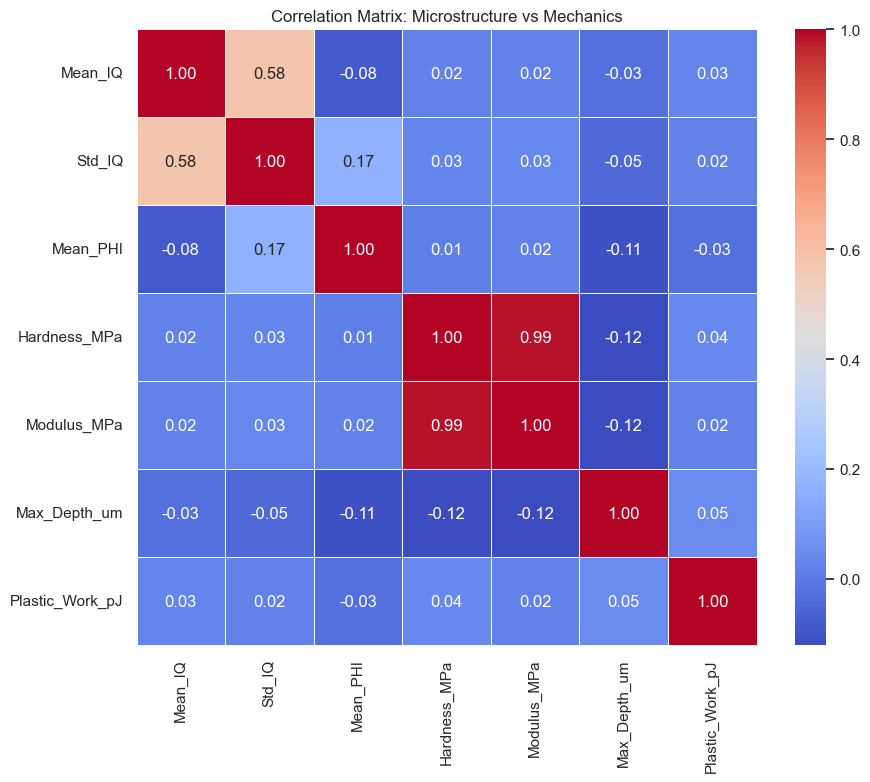

In [4]:
# Select columns for correlation
corr_cols = ['Mean_IQ', 'Std_IQ', 'Mean_PHI', 'Hardness_MPa', 'Modulus_MPa', 'Max_Depth_um', 'Plastic_Work_pJ']
corr_matrix = df_ML[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix: Microstructure vs Mechanics")
plt.show()

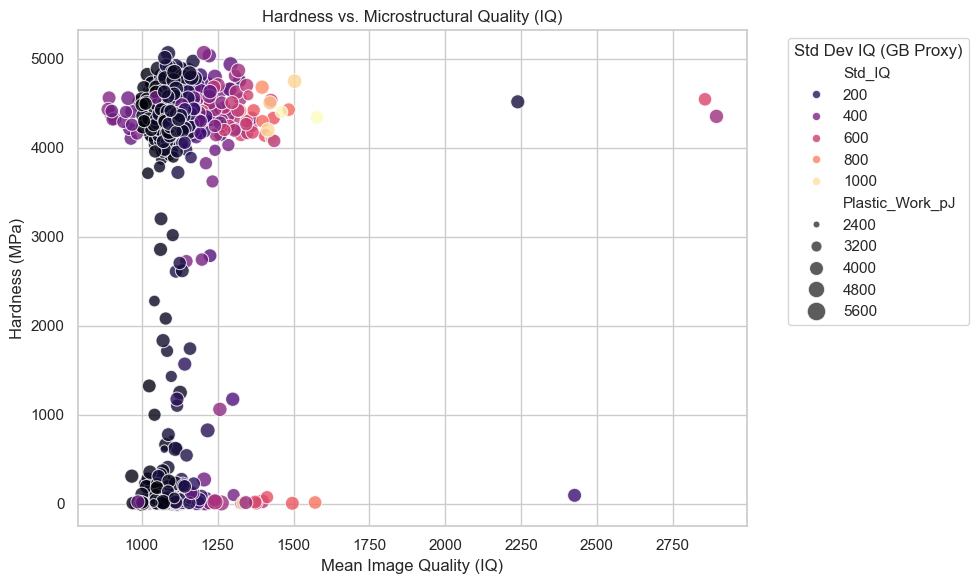

In [5]:
plt.figure(figsize=(10, 6))

# Scatter plot with size and color mapping
scatter = sns.scatterplot(
    data=df_ML, 
    x='Mean_IQ', 
    y='Hardness_MPa', 
    hue='Std_IQ',       # Color by heterogeneity (Grain Boundaries)
    size='Plastic_Work_pJ', # Size by energy absorbed
    sizes=(20, 200),
    palette='magma',
    alpha=0.8
)

plt.title("Hardness vs. Microstructural Quality (IQ)")
plt.xlabel("Mean Image Quality (IQ)")
plt.ylabel("Hardness (MPa)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Std Dev IQ (GB Proxy)")
plt.tight_layout()
plt.show()

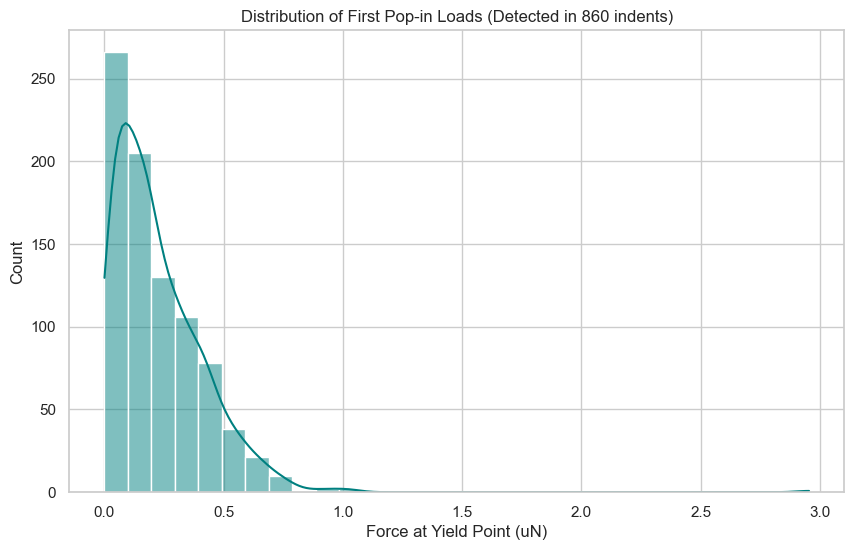

In [6]:
plt.figure(figsize=(10, 6))

# Filter out indents where no pop-in was detected (NaNs)
pop_in_data = df_ML.dropna(subset=['PopIn_Load_uN'])

sns.histplot(pop_in_data['PopIn_Load_uN'], bins=30, kde=True, color='teal')
plt.title(f"Distribution of First Pop-in Loads (Detected in {len(pop_in_data)} indents)")
plt.xlabel("Force at Yield Point (uN)")
plt.ylabel("Count")
plt.show()

Filtered out 435 bad indents. Remaining: 564


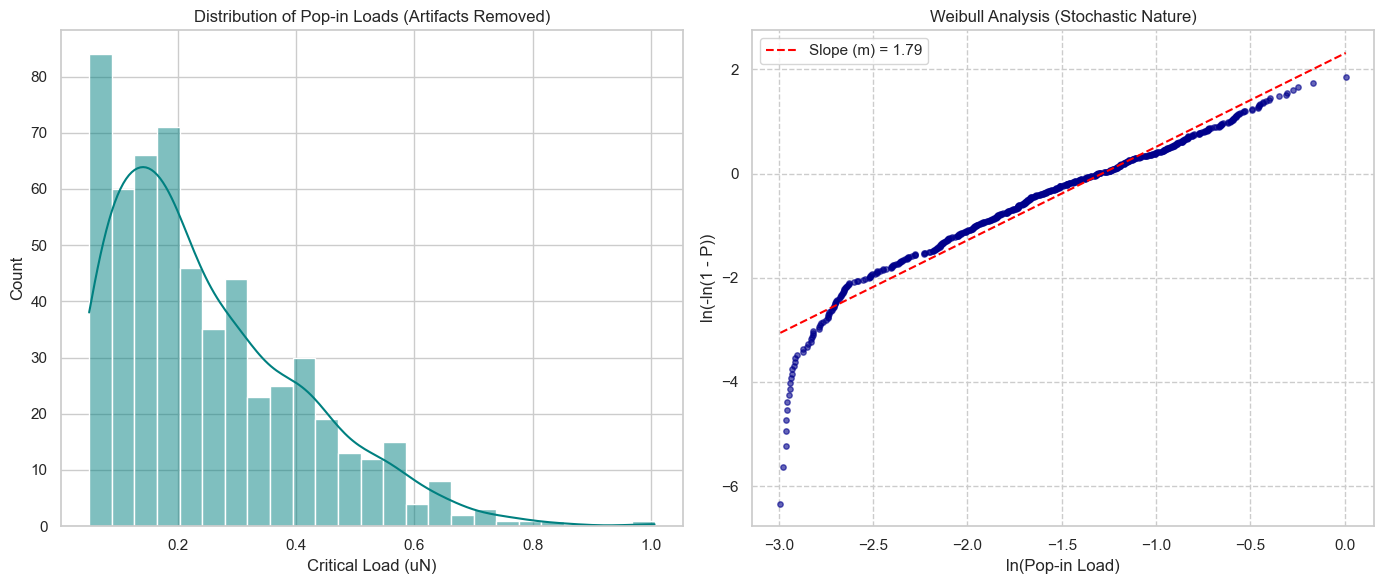

--- SCIENTIFIC INTERPRETATION ---
Weibull Modulus (m) = 1.79
Result: Low 'm' (<10) implies high scatter.
Mechanism: Likely 'Defect Activation' (probabilistic finding of pre-existing dislocations).


In [7]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. FILTERING ARTIFACTS
# ----------------------
# Remove 'dead' indents (e.g., Hardness < 500 MPa or Pop-in < 0.01 uN)
clean_df = df_ML[
    (df_ML['Hardness_MPa'] > 500) & 
    (df_ML['PopIn_Load_uN'] > 0.05)
].copy()

print(f"Filtered out {len(df_ML) - len(clean_df)} bad indents. Remaining: {len(clean_df)}")

# 2. THE "PUBLISHABLE" PLOT: CUMULATIVE PROBABILITY (MORRIS ANALYSIS)
# -------------------------------------------------------------------
# Sort the pop-in loads
pop_in_loads = np.sort(clean_df['PopIn_Load_uN'])
n = len(pop_in_loads)

# Calculate Cumulative Probability P (Rank Order)
# P = i / (N + 1) is the standard estimator
P = np.arange(1, n + 1) / (n + 1)

# Linearize for Weibull Plot: ln(-ln(1-P)) vs ln(Load)
y_weibull = np.log(-np.log(1 - P))
x_weibull = np.log(pop_in_loads)

# Plotting
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot A: The Cleaned Histogram (Physics View)
sns.histplot(pop_in_loads, bins=25, kde=True, color='teal', ax=axes[0])
axes[0].set_title("Distribution of Pop-in Loads (Artifacts Removed)")
axes[0].set_xlabel("Critical Load (uN)")

# Plot B: The Weibull / Morris Plot (Statistical View)
axes[1].scatter(x_weibull, y_weibull, color='darkblue', alpha=0.6, s=15)
axes[1].set_title("Weibull Analysis (Stochastic Nature)")
axes[1].set_xlabel("ln(Pop-in Load)")
axes[1].set_ylabel("ln(-ln(1 - P))")
axes[1].grid(True, which="both", ls="--")

# Add trendline to check slope (Weibull Modulus 'm')
m, c = np.polyfit(x_weibull, y_weibull, 1)
axes[1].plot(x_weibull, m*x_weibull + c, 'r--', label=f'Slope (m) = {m:.2f}')
axes[1].legend()

plt.tight_layout()
plt.show()

# Interpretation text
print(f"--- SCIENTIFIC INTERPRETATION ---")
print(f"Weibull Modulus (m) = {m:.2f}")
if m > 20:
    print("Result: High 'm' (>20) implies highly consistent pop-ins.")
    print("Mechanism: Likely 'Homogeneous Nucleation' (approaching theoretical strength).")
else:
    print("Result: Low 'm' (<10) implies high scatter.")
    print("Mechanism: Likely 'Defect Activation' (probabilistic finding of pre-existing dislocations).")